In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import time

In [ ]:
# Data augmentation for training
train_transform = transforms.Compose([
    transforms.RandomCrop(28, padding=2),
    transforms.RandomRotation(10),
    transforms.ToTensor()
])

# Transform for testing
test_transform = transforms.ToTensor()

# Load training dataset
train_data = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=train_transform
)

# Load testing dataset
test_data = torchvision.datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=test_transform
)

train_loader = torch.utils.data.DataLoader(
    train_data, batch_size=128, shuffle=True
)

test_loader = torch.utils.data.DataLoader(
    test_data, batch_size=128, shuffle=False
)

print("Training images:", len(train_data))
print("Testing images:", len(test_data))

100%|██████████| 9.91M/9.91M [00:00<00:00, 20.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 483kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.49MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.97MB/s]

Training images: 60000
Testing images: 10000


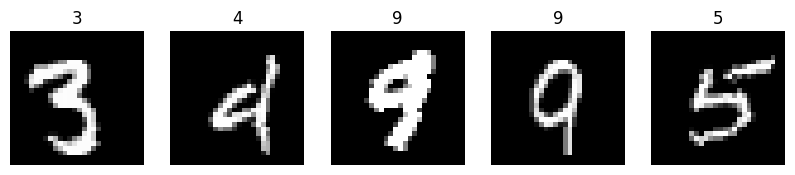

In [ ]:
images, labels = next(iter(train_loader))

plt.figure(figsize=(10, 4))

for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(images[i].squeeze(), cmap="gray")
    plt.title(labels[i].item())
    plt.axis("off")

plt.show()

In [ ]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(1, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)

        self.pool = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))

        x = x.view(x.size(0), -1)

        x = self.relu(self.fc1(x))
        x = self.fc2(x)

        return x

In [ ]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.model = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 512),
            nn.ReLU(),
            nn.Linear(512, 10)
        )

    def forward(self, x):
        return self.model(x)

In [ ]:
def train_model(model, epochs=3):

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    train_losses = []
    test_accuracies = []

    start = time.time()

    for epoch in range(epochs):

        # Training
        model.train()
        total_loss = 0

        for images, labels in train_loader:
            outputs = model(images)
            loss = criterion(outputs, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        train_losses.append(total_loss / len(train_loader))

        # Testing
        model.eval()
        correct = 0
        total = 0

        with torch.no_grad():
            for images, labels in test_loader:
                outputs = model(images)
                predicted = outputs.argmax(dim=1)

                correct += (predicted == labels).sum().item()
                total += labels.size(0)

        accuracy = 100 * correct / total
        test_accuracies.append(accuracy)

        print(
            f"Epoch {epoch+1}/{epochs} "
            f"Loss: {train_losses[-1]:.4f} "
            f"Test Accuracy: {accuracy:.2f}%"
        )

    training_time = time.time() - start

    return train_losses, test_accuracies, training_time

In [ ]:
# Train CNN
cnn = CNN()

cnn_loss, cnn_acc, cnn_time = train_model(
    cnn, epochs=3
)

# Train MLP
mlp = MLP()

mlp_loss, mlp_acc, mlp_time = train_model(
    mlp, epochs=3
)

Epoch 1/3 Loss: 0.3867 Test Accuracy: 98.09%
Epoch 2/3 Loss: 0.1190 Test Accuracy: 98.66%
Epoch 3/3 Loss: 0.0872 Test Accuracy: 98.73%
Epoch 1/3 Loss: 0.5627 Test Accuracy: 95.90%
Epoch 2/3 Loss: 0.2125 Test Accuracy: 96.67%
Epoch 3/3 Loss: 0.1638 Test Accuracy: 97.18%


In [ ]:
print("CNN Test Accuracy:", round(cnn_acc[-1], 2), "%")
print("MLP Test Accuracy:", round(mlp_acc[-1], 2), "%")

print("CNN Training Time:", round(cnn_time, 2), "seconds")
print("MLP Training Time:", round(mlp_time, 2), "seconds")

CNN Test Accuracy: 98.73 %
MLP Test Accuracy: 97.18 %
CNN Training Time: 193.01 seconds
MLP Training Time: 60.51 seconds


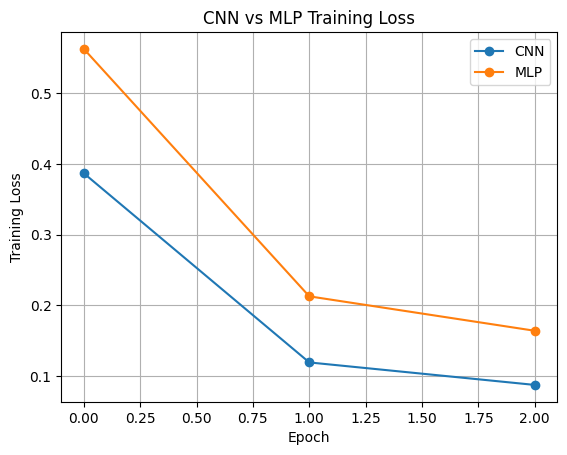

In [ ]:
plt.plot(cnn_loss, marker="o", label="CNN")
plt.plot(mlp_loss, marker="o", label="MLP")

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("CNN vs MLP Training Loss")
plt.legend()
plt.grid()
plt.show()

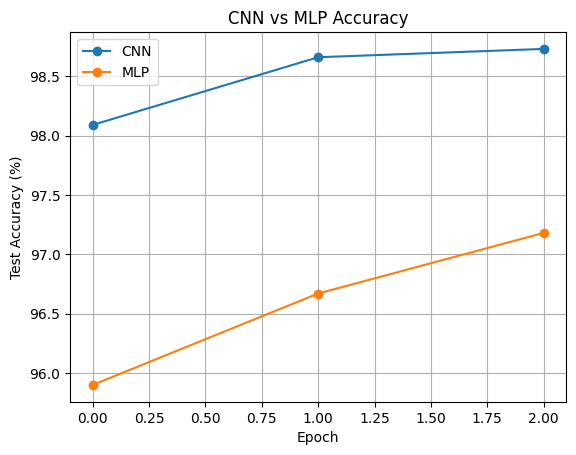

In [ ]:
plt.plot(cnn_acc, marker="o", label="CNN")
plt.plot(mlp_acc, marker="o", label="MLP")

plt.xlabel("Epoch")
plt.ylabel("Test Accuracy (%)")
plt.title("CNN vs MLP Accuracy")
plt.legend()
plt.grid()
plt.show()

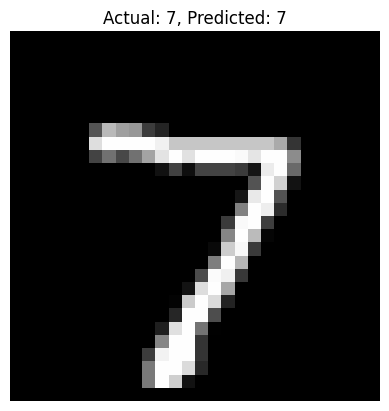

In [ ]:
cnn.eval()

image, label = test_data[0]

with torch.no_grad():
    output = cnn(image.unsqueeze(0))
    prediction = output.argmax(dim=1).item()

plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Actual: {label}, Predicted: {prediction}")
plt.axis("off")
plt.show()